# 07 — Valor esperado y segmentación con K-Means

**Objetivo:** convertir las predicciones en **decisiones de cobranza**: cuánto se espera recuperar de cada crédito, a qué segmento pertenece y qué acción y canal le corresponden.

- **Valor esperado bruto** = P(recuperar) × tasa media de recuperación × saldo estimado al default (D36)
- **Valor esperado neto** = bruto × efectividad del canal − costo del canal (**supuestos simulados**, `src/supuestos.py`)
- **K-Means** sobre P(recuperar) y saldo: grupos con nombre y acción asignados por una regla transparente.

**Resultados que guarda:** tablas `canales`, `segmentos` y `predicciones` en PostgreSQL (las lee Power BI), `models/segmentador.joblib`, `docs/segmentos_*.csv` y gráficas `docs/figuras/07_*.png`.

## 1. Preparación

In [1]:
import sys, json, warnings
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sqlalchemy import text

from src.config import RUTAS
from src.bd import obtener_motor
from src.variables import leer_base, construir_variables, saldo_al_default
from src.segmentacion import evaluar_k, Segmentador, valor_esperado, es_fpd
from src.metricas import captura_en
from src.supuestos import CANALES

warnings.filterwarnings('ignore')
pd.set_option('display.width', 180)
MODELO_VERSION = 'lgbm_A_v1'

def guardar_figura(fig, nombre):
    fig.savefig(RUTAS['figuras'] / nombre, dpi=150, bbox_inches='tight')

## 2. Datos, modelo y saldo estimado

In [2]:
motor = obtener_motor()
base = leer_base(motor)
X = construir_variables(base)
modelo_A = joblib.load(RUTAS['models'] / 'modelo_A.joblib')
metricas = json.loads((RUTAS['models'] / 'metricas.json').read_text(encoding='utf-8'))

saldo = saldo_al_default(base)
base['saldo_estimado'] = saldo.fillna(base['monto_original'] * metricas['ratio_saldo_mediano'])
base['saldo_log'] = np.log1p(base['saldo_estimado'])

# Tasa media de recuperación cuando hay recuperación, SOLO con entrenamiento (D36)
ent = base['conjunto'].eq('entrenamiento')
TASA_MEDIA = float(base.loc[ent & base['objetivo_a'].eq(1), 'objetivo_b_tasa'].mean())
print(f'Modelo A: {metricas["modelo_A"]} | variables: {len(modelo_A.variables)}')
print(f'Tasa media de recuperación (entrenamiento, A=1): {TASA_MEDIA:.4f}')

Modelo A: LightGBM | variables: 33
Tasa media de recuperación (entrenamiento, A=1): 0.3218


## 3. Predecir P(recuperar) para toda la cartera
Se excluyen solo los créditos sin exposición. Nota: en el **entrenamiento** la probabilidad es *dentro de muestra* (más optimista); las conclusiones se sacan con **validación** e **inmadura**.

In [3]:
cartera = base[base['conjunto'] != 'excluida'].copy()
cartera['prob_recuperar'] = modelo_A.predict_proba(X.loc[cartera.index])
print(cartera.groupby('conjunto')['prob_recuperar'].describe()[['count', 'mean', '25%', '50%', '75%']].round(3))

                count   mean    25%    50%    75%
conjunto                                         
entrenamiento  8543.0  0.254  0.177  0.221  0.275
inmadura       5196.0  0.241  0.182  0.218  0.265
validacion     3163.0  0.256  0.185  0.217  0.261


## 4. Elegir k
Se ajusta K-Means sobre la **validación sin el grupo FPD** (sección 5) (predicciones fuera de muestra), con logit(P) y log(saldo).

**Regla:** la mejor **silueta** entre k = 4 y 6 con ningún segmento menor al 3 % de la cartera. ¿Por qué no k = 2 o 3? Hay **4 acciones** de cobranza; además, la silueta tiende a premiar separar un grupo pequeño y extremo del resto, lo que no sirve para operar.

📋 **Pega esta tabla.**

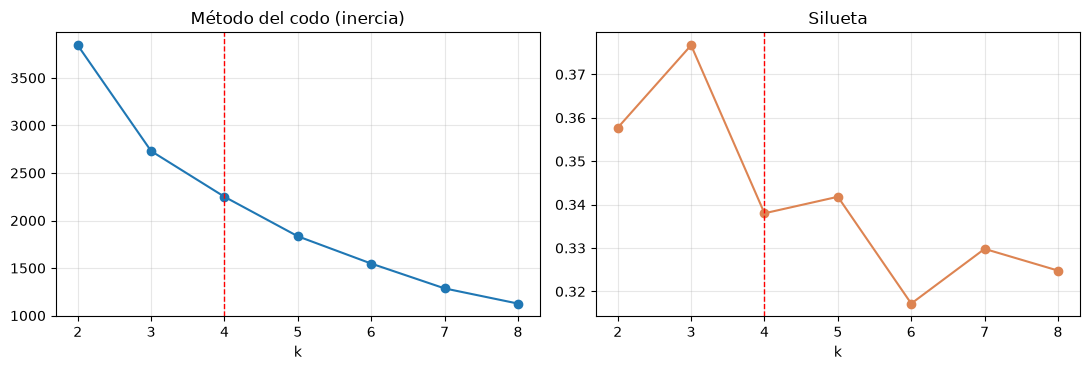

✅ k elegido: 4


,inercia,segmento_mas_pequeno_pct,silueta
k,,,
2,3843.5,47.6,0.3577
3,2730.8,23.1,0.3767
4,2249.8,13.3,0.3380
5,1834.0,0.2,0.3418
6,1547.3,0.2,0.3172
7,1286.2,0.2,0.3298
8,1126.6,0.2,0.3248


In [4]:
valid = cartera[cartera['conjunto'] == 'validacion']
evaluacion_k = evaluar_k(valid)
validos = evaluacion_k.loc[4:6].query('segmento_mas_pequeno_pct >= 3')
K = int((validos if len(validos) else evaluacion_k.loc[4:6])['silueta'].idxmax())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(evaluacion_k.index, evaluacion_k['inercia'], marker='o'); axes[0].set_title('Método del codo (inercia)')
axes[1].plot(evaluacion_k.index, evaluacion_k['silueta'], marker='o', color='#DD8452'); axes[1].set_title('Silueta')
for ax in axes:
    ax.axvline(K, color='red', ls='--', lw=1); ax.set_xlabel('k'); ax.grid(alpha=.3)
plt.tight_layout(); guardar_figura(fig, '07_eleccion_k.png'); plt.show()
print(f'✅ k elegido: {K}')
evaluacion_k

## 5. Segmentar y nombrar
**Paso 1 — regla de negocio:** los créditos que cayeron en default en la **cuota 0 o 1** (*First Payment Default*, señal clásica de fraude en banca) forman el **segmento 1** y se gestionan aparte (ver sección 6b).

**Paso 2 — K-Means** sobre el resto; cada grupo se nombra comparando su centro con las medianas:

| | Saldo bajo | Saldo alto |
|---|---|---|
| **P alta** | Recordatorio automático (WhatsApp) | Negociación prioritaria (asesor) |
| **P baja** | Baja recuperación / venta de cartera | Contacto selectivo (llamada) |

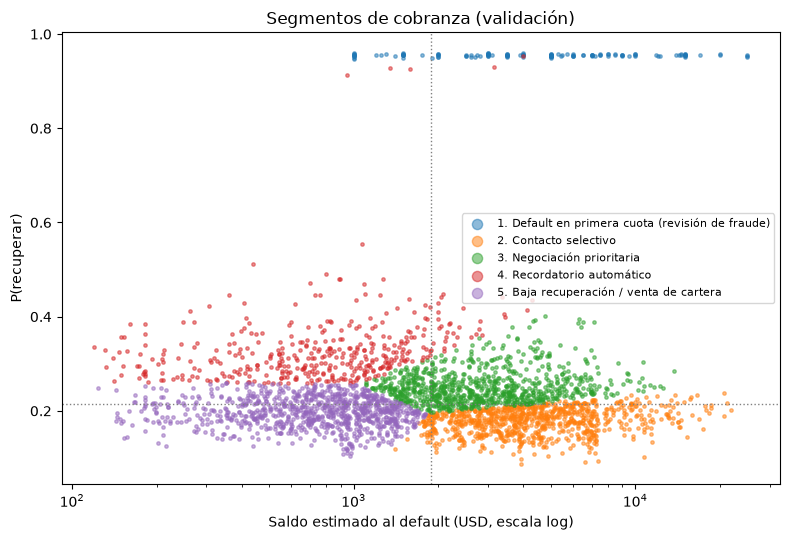

,segmento_id,nombre,canal_sugerido,descripcion
0,1,Default en primera cuota (revisión de fraude),Negociación con asesor,Cayó en default en la cuota 0-1: patrón típico...
1,2,Contacto selectivo,Llamada de asesor,Baja probabilidad pero saldo alto: vale un con...
2,3,Negociación prioritaria,Negociación con asesor,Alta probabilidad y saldo alto: donde más dine...
3,4,Recordatorio automático,WhatsApp,Alta probabilidad de pago y saldo bajo: un rec...
4,5,Baja recuperación / venta de cartera,Venta de cartera,Baja probabilidad y saldo bajo: gestionar cues...


In [5]:
seg = Segmentador(K).fit(valid)
cartera['segmento_id'] = seg.predict(cartera)
catalogo = seg.tabla_segmentos()
cartera = cartera.merge(catalogo[['segmento_id', 'nombre', 'canal_sugerido']], on='segmento_id', how='left')

fig, ax = plt.subplots(figsize=(8, 5.5))
v = cartera[cartera['conjunto'] == 'validacion']
for (sid, nombre), g in v.groupby(['segmento_id', 'nombre']):
    ax.scatter(g['saldo_estimado'], g['prob_recuperar'], s=6, alpha=.5, label=f'{sid}. {nombre}')
ax.set_xscale('log'); ax.set_xlabel('Saldo estimado al default (USD, escala log)'); ax.set_ylabel('P(recuperar)')
ax.axhline(seg.mediana_p_, color='gray', ls=':', lw=1); ax.axvline(np.expm1(seg.mediana_saldo_), color='gray', ls=':', lw=1)
ax.set_title('Segmentos de cobranza (validación)'); ax.legend(markerscale=3, fontsize=8)
plt.tight_layout(); guardar_figura(fig, '07_segmentos.png'); plt.show()
catalogo[['segmento_id', 'nombre', 'canal_sugerido', 'descripcion']]

## 6. Perfil de cada segmento con resultados REALES (validación)
La prueba de que los segmentos sirven: ¿los que el modelo pone arriba **realmente** recuperaron más? Comparamos también los USD esperados con los USD reales.

📋 **Pega esta tabla** (es la tabla central de la Fase 7).

In [6]:
v = cartera[cartera['conjunto'] == 'validacion'].copy()
v['monto_esperado'] = v['prob_recuperar'] * TASA_MEDIA * v['saldo_estimado']
perfil = (v.groupby(['segmento_id', 'nombre'])
            .agg(creditos=('credito_id', 'size'),
                 p_media=('prob_recuperar', 'mean'),
                 tasa_real_recupera=('objetivo_a', 'mean'),
                 saldo_medio_usd=('saldo_estimado', 'mean'),
                 usd_esperado=('monto_esperado', 'sum'),
                 usd_real=('recuperacion_total', 'sum'))
            .reset_index())
perfil['pct_creditos'] = perfil['creditos'] / perfil['creditos'].sum()
perfil['pct_usd_real'] = perfil['usd_real'] / perfil['usd_real'].sum()
perfil['usd_real_por_credito'] = perfil['usd_real'] / perfil['creditos']
perfil.round(3)

,segmento_id,nombre,creditos,p_media,tasa_real_recupera,saldo_medio_usd,usd_esperado,usd_real,pct_creditos,pct_usd_real,usd_real_por_credito
0,1,Default en primera cuota (revisión de fraude),134,0.955,0.978,6127.985,252435.429,252574.00,0.042,0.214,1884.881
1,2,Contacto selectivo,855,0.178,0.223,5117.976,256510.266,379017.10,0.270,0.321,443.295
2,3,Negociación prioritaria,847,0.252,0.276,3247.874,226227.429,347614.80,0.268,0.294,410.407
3,4,Recordatorio automático,404,0.333,0.408,944.962,43727.227,116497.40,0.128,0.099,288.360
4,5,Baja recuperación / venta de cartera,923,0.197,0.236,812.969,47284.424,86512.77,0.292,0.073,93.730


## 6b. ¿Quiénes son los créditos con probabilidad muy alta?
En la primera ejecución, el grupo con P ≈ 0,96 resultó ser casi entero de créditos con default en la **cuota 0 o 1** (*First Payment Default*). `estado_credito` se muestra **solo para interpretar**.

📋 **Pega esta tabla.**

In [7]:
v = cartera[cartera['conjunto'] == 'validacion']
alta = v['prob_recuperar'] >= 0.8
cols = ['cuota_primer_default', 'proporcion_plazo_pagada', 'pct_saldo_pendiente_estimado',
        'moras_7_anios', 'ingreso_mensual_log', 'calificacion_ord']
Xv = X.loc[base['conjunto'] == 'validacion', cols].reset_index(drop=True)
perfil_alta = pd.DataFrame({'P >= 0,8': Xv[alta.to_numpy()].median(), 'resto': Xv[~alta.to_numpy()].median()})
perfil_alta.loc['% Defaulted (solo interpretación)'] = [
    (v.loc[alta, 'estado_credito'] == 'Defaulted').mean() * 100, (v.loc[~alta, 'estado_credito'] == 'Defaulted').mean() * 100]
perfil_alta.loc['créditos'] = [alta.sum(), (~alta).sum()]
print('Distribución de cuota_primer_default en P >= 0,8:')
print(Xv.loc[alta.to_numpy(), 'cuota_primer_default'].value_counts().head(8).to_string())
perfil_alta.round(3)

Distribución de cuota_primer_default en P >= 0,8:
cuota_primer_default
1.0    124
0.0     10
2.0      1


,"P >= 0,8",resto
cuota_primer_default,1.000,25.000
proporcion_plazo_pagada,0.028,0.694
pct_saldo_pendiente_estimado,1.000,0.497
moras_7_anios,0.000,0.000
ingreso_mensual_log,8.230,8.230
calificacion_ord,4.000,3.000
% Defaulted (solo interpretación),44.604,24.140
créditos,139.000,3024.000


## 6c. Sensibilidad: ¿cuánto del valor depende del grupo FPD?
Si buena parte de la recuperación del grupo FPD es una **recompra de la plataforma** (y no cobranza), no sería trasladable a un banco. Medimos la captura de USD **con y sin** ese grupo.

📋 **Pega esta tabla.**

In [8]:
v = cartera[cartera['conjunto'] == 'validacion']
fpd_v = es_fpd(v).to_numpy()
rng = np.random.default_rng(42)
filas = []
for nombre, m in [('Con FPD', np.ones(len(v), bool)), ('Sin FPD', ~fpd_v)]:
    g = v[m]
    puntaje = (g['prob_recuperar'] * g['saldo_estimado']).to_numpy()
    usd = g['recuperacion_total'].to_numpy()
    filas.append({'escenario': nombre, 'creditos': len(g), 'usd_recuperado': round(usd.sum(), 0),
                  'captura_top10_modelo': round(captura_en(puntaje, usd, 0.1), 4),
                  'captura_top20_modelo': round(captura_en(puntaje, usd, 0.2), 4),
                  'captura_top20_azar': round(captura_en(rng.random(len(g)), usd, 0.2), 4)})
sensibilidad_fpd = pd.DataFrame(filas)
print(f'Créditos FPD en validación: {fpd_v.sum():,} ({fpd_v.mean():.1%}) | '
      f'USD recuperados por FPD: {v.loc[fpd_v, "recuperacion_total"].sum():,.0f} '
      f'({v.loc[fpd_v, "recuperacion_total"].sum() / v["recuperacion_total"].sum():.1%})')
sensibilidad_fpd

Créditos FPD en validación: 134 (4.2%) | USD recuperados por FPD: 252,574 (21.4%)


,escenario,creditos,usd_recuperado,captura_top10_modelo,captura_top20_modelo,captura_top20_azar
0,Con FPD,3163,1182216.0,0.3746,0.5293,0.2264
1,Sin FPD,3029,929642.0,0.3056,0.4575,0.1862


## 7. Valor esperado neto y prioridad
Aplicamos el costo y la efectividad del canal de cada segmento (**supuestos simulados** de `src/supuestos.py`). La **prioridad** ordena cada conjunto de mayor a menor valor esperado neto.

📋 **Pega esta tabla.**

In [9]:
ve = valor_esperado(cartera['prob_recuperar'].to_numpy(), cartera['saldo_estimado'].to_numpy(),
                    TASA_MEDIA, cartera['canal_sugerido'])
cartera = pd.concat([cartera.reset_index(drop=True), ve], axis=1)
cartera['prioridad'] = (cartera.groupby('conjunto')['valor_esperado']
                          .rank(ascending=False, method='first').astype(int))

print('Supuestos de canal (simulados):')
display(pd.DataFrame(CANALES)[['nombre', 'costo_por_contacto_usd', 'efectividad_supuesta']])

resumen_ve = (cartera[cartera['conjunto'].isin(['validacion', 'inmadura'])]
              .groupby(['conjunto', 'segmento_id', 'nombre'])
              .agg(creditos=('credito_id', 'size'), monto_esperado_usd=('monto_esperado', 'sum'),
                   costo_usd=('costo_gestion', 'sum'), valor_esperado_neto_usd=('valor_esperado', 'sum'),
                   pct_ve_negativo=('valor_esperado', lambda s: (s < 0).mean()))
              .round(2))
resumen_ve

Supuestos de canal (simulados):


,nombre,costo_por_contacto_usd,efectividad_supuesta
0,SMS,0.05,0.40
1,WhatsApp,0.10,0.55
2,Llamada de asesor,3.00,0.80
3,Negociación con asesor,15.00,1.00
4,Venta de cartera,0.00,NaN


creditos  monto_esperado_usd  costo_usd  valor_esperado_neto_usd  pct_ve_negativo
conjunto   segmento_id nombre                                                                                                                          
inmadura   1           Default en primera cuota (revisión de fraude)        83           119125.80     1245.0                117880.80              0.0
           2           Contacto selectivo                                 2359           959387.58     7077.0                760433.06              0.0
           3           Negociación prioritaria                            2129           872530.56    31935.0                840595.56              0.0
           4           Recordatorio automático                             309            92810.61       30.9                 51014.94              0.0
           5           Baja recuperación / venta de cartera                316            19724.32        0.0                     0.00              0.0
validacion 1           Default en primera cuota (revisión de fraude)       134           252435.43     2010.0                250425.43              0.0
           2           Contacto selectivo                                  855           256510.27     2565.0                202643.21              0.0
           3           Negociación prioritaria                             847           226227.43    12705.0                213522.43              0.0
           4           Recordatorio automático                             404            43727.23       40.4                 24009.57              0.0
           5           Baja recuperación / venta de cartera                923            47284.42        0.0                     0.00              0.0

## 8. Guardar en PostgreSQL
Se reemplazan los catálogos y las predicciones (idempotente). Power BI y la aplicación las leen desde `vw_cartera_cobranza`.

In [10]:
predicciones = pd.DataFrame({
    'credito_id': cartera['credito_id'].astype(int),
    'modelo_version': MODELO_VERSION,
    'es_vigente': True,
    'prob_recuperar': cartera['prob_recuperar'].round(6),
    'tasa_esperada': round(TASA_MEDIA, 6),
    'monto_esperado': cartera['monto_esperado'].round(2),
    'costo_gestion': cartera['costo_gestion'].round(2),
    'valor_esperado': cartera['valor_esperado'].round(2),
    'segmento_id': cartera['segmento_id'].astype(int),
    'prioridad': cartera['prioridad'].astype(int),
})

with motor.begin() as con:
    con.exec_driver_sql('TRUNCATE campana_asignaciones, campanas, predicciones, segmentos, canales RESTART IDENTITY')
    pd.DataFrame(CANALES).to_sql('canales', con, if_exists='append', index=False)
    catalogo.to_sql('segmentos', con, if_exists='append', index=False)
    predicciones.to_sql('predicciones', con, if_exists='append', index=False, method='multi', chunksize=1000)

with motor.connect() as con:
    n = con.execute(text('SELECT COUNT(*) FROM predicciones WHERE es_vigente')).scalar()
print(f'✅ PostgreSQL: {len(CANALES)} canales, {len(catalogo)} segmentos, {n:,} predicciones vigentes')

✅ PostgreSQL: 5 canales, 5 segmentos, 16,902 predicciones vigentes


## 9. Verificar lo que verá Power BI (usuario de solo lectura)
📋 **Pega esta tabla.**

In [11]:
motor_bi = obtener_motor(rol='lector')
with motor_bi.connect() as con:
    vista = pd.read_sql(text("""
        SELECT conjunto, segmento, canal_sugerido, COUNT(*) AS creditos,
               ROUND(AVG(prob_recuperar)::numeric, 3) AS p_media,
               ROUND(SUM(valor_esperado)::numeric, 0) AS valor_esperado_usd
        FROM vw_cartera_cobranza
        WHERE conjunto IN ('validacion', 'inmadura')
        GROUP BY conjunto, segmento, canal_sugerido
        ORDER BY conjunto, valor_esperado_usd DESC"""), con)
motor_bi.dispose()
vista

,conjunto,segmento,canal_sugerido,creditos,p_media,valor_esperado_usd
0,inmadura,Negociación prioritaria,Negociación con asesor,2129,0.267,840596.0
1,inmadura,Contacto selectivo,Llamada de asesor,2359,0.180,760433.0
2,inmadura,Default en primera cuota (revisión de fraude),Negociación con asesor,83,0.955,117881.0
3,inmadura,Recordatorio automático,WhatsApp,309,0.380,51015.0
4,inmadura,Baja recuperación / venta de cartera,Venta de cartera,316,0.197,0.0
5,validacion,Default en primera cuota (revisión de fraude),Negociación con asesor,134,0.955,250425.0
6,validacion,Negociación prioritaria,Negociación con asesor,847,0.252,213523.0
7,validacion,Contacto selectivo,Llamada de asesor,855,0.178,202643.0
8,validacion,Recordatorio automático,WhatsApp,404,0.333,24010.0
9,validacion,Baja recuperación / venta de cartera,Venta de cartera,923,0.197,0.0


## 10. Guardar archivos

In [12]:
joblib.dump(seg, RUTAS['models'] / 'segmentador.joblib')
metricas['segmentacion'] = {'k': K, 'tasa_media_entrenamiento': TASA_MEDIA,
                            'modelo_version': MODELO_VERSION}
(RUTAS['models'] / 'metricas.json').write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding='utf-8')
evaluacion_k.to_csv(RUTAS['docs'] / 'segmentos_eleccion_k.csv', encoding='utf-8-sig')
perfil.to_csv(RUTAS['docs'] / 'segmentos_perfil_validacion.csv', index=False, encoding='utf-8-sig')
resumen_ve.to_csv(RUTAS['docs'] / 'segmentos_valor_esperado.csv', encoding='utf-8-sig')
sensibilidad_fpd.to_csv(RUTAS['docs'] / 'segmentos_sensibilidad_fpd.csv', index=False, encoding='utf-8-sig')
catalogo.to_csv(RUTAS['docs'] / 'segmentos_catalogo.csv', index=False, encoding='utf-8-sig')
print('✅ models/segmentador.joblib, models/metricas.json, docs/segmentos_*.csv, docs/figuras/07_*.png')

✅ models/segmentador.joblib, models/metricas.json, docs/segmentos_*.csv, docs/figuras/07_*.png
